# Supply Disturbance and Gate Drive in a SKY130 PFET Regulator

**Author:** Christian Reivan

**Affiliation:**

**GitHub:** [christianreivan](https://github.com/christianreivan)

Supply rejection depends on the pass transistor output resistance, the amplitude and phase of its gate ripple, and the finite current available to charge that gate. This notebook develops a connected 50 mA PFET regulator using public SKY130 models and ngspice. Explicit terminal equations guide the transistor changes, followed by native DC, AC, pole and load transition experiments.

A longer pass channel operated at stronger inversion reduces the output resistance disturbance. A parallel supply sourced helper and increased local driver current compensate the added gate charge. A 1 pF capacitor between output and pass gate provides a fast reciprocal charge path. The selected nominal circuit improves the complete sampled 1 to 10 MHz band by at least 4.45 dB relative to the original connected core, improves low frequency rejection, and improves both extrema of the declared load transition. The output capacitor remains 200 pF.

The notebook retains unsuccessful alternatives to explain the design decisions. The improvements are demonstrated at TT and 27 °C with ideal external reference and bias ports. A separate fixed bias corner screen establishes the remaining process and temperature limits. No silicon measurement, layout extraction, complete regulator qualification, or circuit novelty is claimed.


## Reproduction

Run this notebook from its project directory with Python 3, NumPy, Matplotlib, IPython and ngspice available. The Python requirements are recorded in `requirements.txt`. Set `NGSPICE_EXE` to the simulator executable if ngspice is not on PATH. The recorded execution uses ngspice 47. The model files are bundled with their original license, pinned source revision and hashes. No remote laboratory service is used.

Executing all cells reruns the native simulations. A completed simulation is not treated as proof that a design requirement has passed. All comparisons retain the failed cases. Default diffusion areas and perimeters are zero in these model wrappers. The results include intrinsic and default model capacitance but do not qualify a physical layout.


In [1]:
from pathlib import Path
import json, os, subprocess, sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

PROJECT = Path.cwd()
assert (PROJECT / "project_metadata.json").is_file(), "Open this notebook in its project folder."
sys.path.insert(0, str(PROJECT / "scripts"))
from runtime_support import find_ngspice, verify_models, record_simulator

simulator = find_ngspice()
verify_models()
provenance = record_simulator(simulator)
print(provenance["version_output"])
metadata = json.loads((PROJECT / "project_metadata.json").read_text())
print("Author:", metadata["authors"][0]["name"])
print("Affiliation:", metadata["authors"][0]["affiliation"])
print("Target branch:", metadata["fork_branch"])

def run_script(name):
    reply = subprocess.run([sys.executable, str(PROJECT / "scripts" / name)],
                           cwd=PROJECT, text=True, capture_output=True, timeout=240)
    (PROJECT / "results" / (name + ".console.txt")).write_text(reply.stdout + "\n" + reply.stderr)
    if reply.returncode:
        raise RuntimeError(reply.stdout[-2500:] + reply.stderr[-2500:])
    print(name, "completed")

def read_result(relative):
    return json.loads((PROJECT / "results" / relative).read_text())

plt.rcParams.update({"font.size": 13, "lines.linewidth": 2.3,
                     "axes.spines.top": False, "axes.spines.right": False})


******
** ngspice-47 : Circuit level simulation program
** Compiled with KLU Direct Linear Solver
** The U. C. Berkeley CAD Group
** Copyright 1985-1994, Regents of the University of California.
** Copyright 2001-2026, The ngspice team.
** Please get your ngspice manual from https://ngspice.sourceforge.io/docs.html
** Please file your bug-reports at https://ngspice.sourceforge.io/bugrep.html
** Creation Date: Aug 11 2026   13:55:25
******
Author: Christian Reivan
Affiliation: 
Target branch: idea2


## Connected circuit and the role of the level shifts

The original source cross connection of two enhancement NFETs gives VGS1 = VS2 − VS1 and VGS2 = VS1 − VS2. Both cannot have positive gate overdrive simultaneously. The implemented evolution inserts level shifts and senses the reference and output at distinct gates.

M1 has D = A, G = R, S = X, B = ground. M2 has D = C, G = O, S = Y, B = ground. L2 shifts the output down to X, while L1 shifts the reference down to Y. In the stiff level shift limit,

$$V_{GS1}=V_{REF}-V_{OUT}+V_{SG,L2},\qquad
V_{GS2}=V_{OUT}-V_{REF}+V_{SG,L1}.$$

P1 and P2 combine the sensing currents at command node C. The circuit contains two coupled negative feedback paths. With C held fixed, an increase in O raises the source voltage of MF and increases its current into G. The rising pass gate reduces the current supplied by MP and opposes the output increase. This direct path through the MF source provides the local follower action.

The precision path acts through the sensing pair and command node C. An output increase raises M2 current and lowers C. The lower MF gate voltage increases its current into G and produces an additional correction through MP. The local path enters MF at its source, while the precision path enters MF at its gate. Both paths act on the same moving G and O nodes, and C also moves when the sensing network is connected. Their separately obtained loop gain magnitudes therefore cannot be multiplied to represent the complete circuit.

MP is the integrated pass transistor array, with D = O, G = G, S = VIN and B = VIN. Its refined geometry is 1923 parallel units, each W = 5 µm and L = 0.15 µm. The total drawn width is 9615 µm. This multiplier is a device model representation, not a completed layout.

MF has D = G, G = C, S = O and B = O. Its output supplied current therefore requires voltage room between O and G. At light load the pass gate must rise, and this voltage room can disappear. The reference port also supplies DC current through L1. A physical reference buffer or equivalent current delivery circuit is needed unless the reference source can supply that current with adequate impedance and rejection.


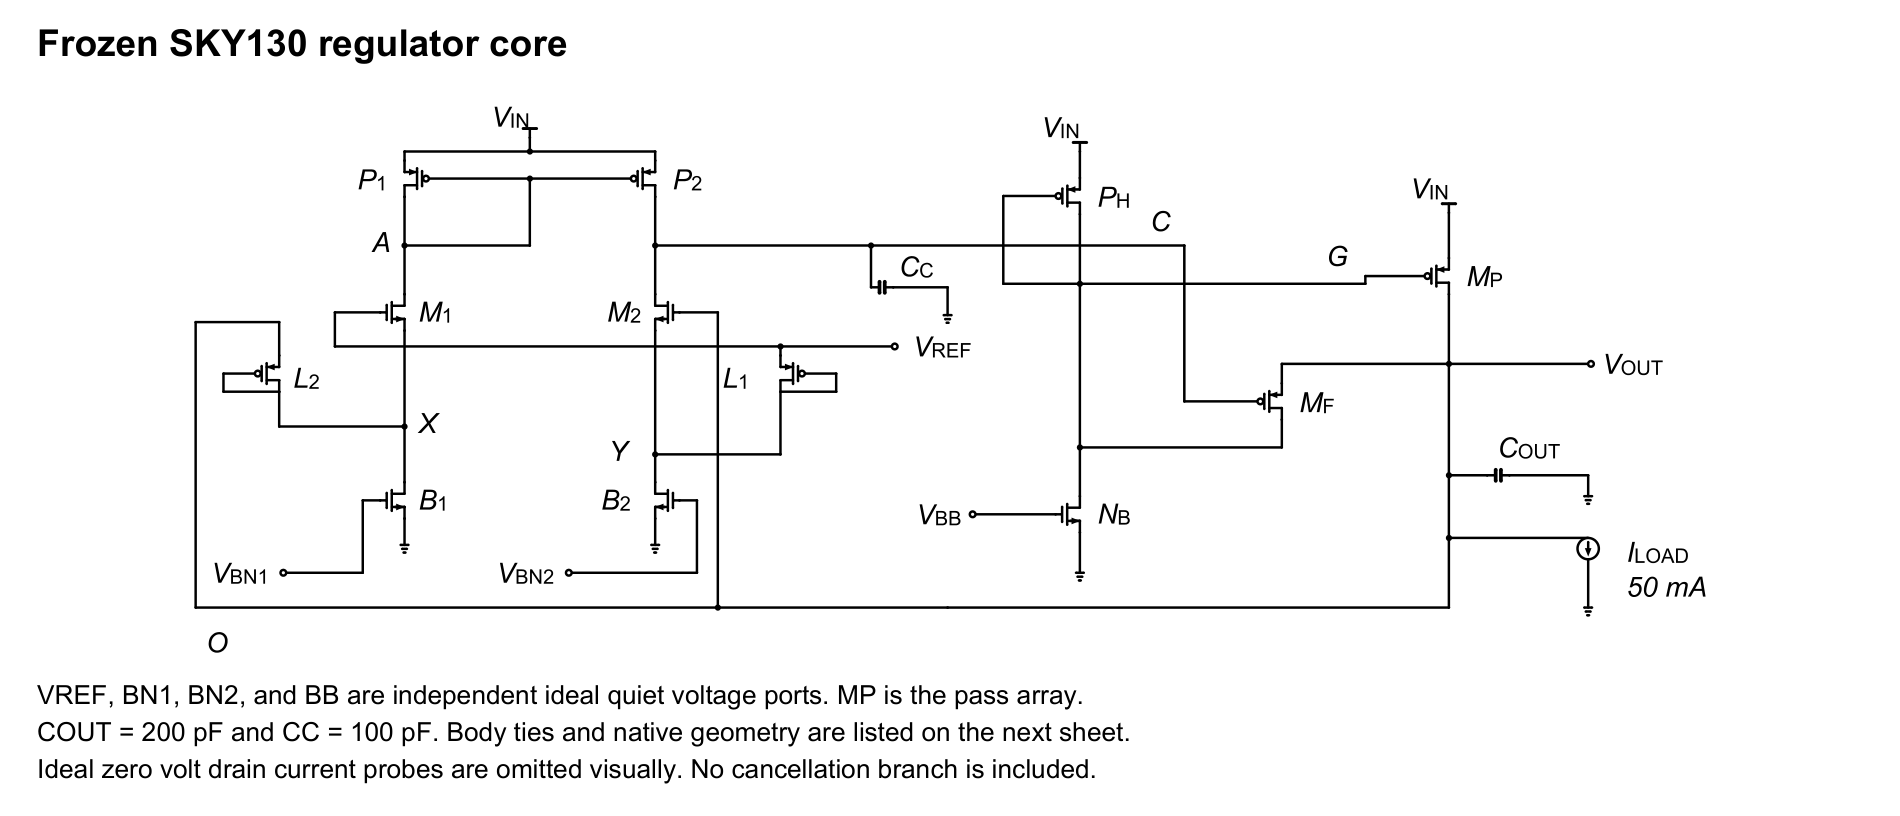

In [2]:
display(Image(filename=str(PROJECT / "figures" / "sky130_core.png")))


## Geometry refinement and current accounting

The baseline sensing pair and mirror used a multiplier of 50 while each level shifter used a multiplier of 1. The refined circuit reduces M1, M2 and P1 to 5, changes P2 from 32 to 3, increases L1 and L2 to 10, and reduces B1 and B2 from 50 to 5. MP changes from 1922 to 1923 units. The remaining device dimensions are fixed. The declared ideal bias voltages are changed once to establish the nominal operating point, then held fixed across each load sweep.

This change strengthens the level shifts relative to the sensing current. It is not an adaptive adjustment at every load. The output capacitor remains 200 pF and the command capacitor remains 100 pF. VIN current minus external load is reported as core overhead. It excludes the separately supplied reference current and the power of reference and bias generators.


In [3]:
run_script("run_core.py")
run_script("run_load_screen.py")
run_script("run_refined.py")
baseline = read_result("load_screen.json")
refined = read_result("refined/summary.json")
rows = refined["load_rows"]
print("Load mA   VOUT V   VIN overhead uA   Reference uA   M2 margin mV   MF margin mV")
for row in rows:
    print(f'{row["external_load_A"]*1e3:7.1f}  {row["voltages_V"]["O"]:.6f}  '
          f'{row["core_input_current_above_external_load_A"]*1e6:15.3f}  '
          f'{row["reference_current_A"]*1e6:12.3f}  '
          f'{row["M2_saturation_margin_V"]*1e3:12.3f}  '
          f'{row["MF_forward_saturation_margin_V"]*1e3:12.3f}')


run_core.py completed


run_load_screen.py completed


run_refined.py completed
Load mA   VOUT V   VIN overhead uA   Reference uA   M2 margin mV   MF margin mV
    0.0  0.827421           55.423        14.230       -56.513       -32.105
    0.1  0.810540           55.968        13.097        -8.220        41.993
    1.0  0.806889           55.155        13.060        13.031       179.054
    5.0  0.804929           54.459        13.105        28.043       280.861
   10.0  0.804055           54.121        13.140        35.546       326.391
   25.0  0.802473           53.566        13.221        50.131       393.536
   50.0  0.799841           52.905        13.392        76.368       454.615


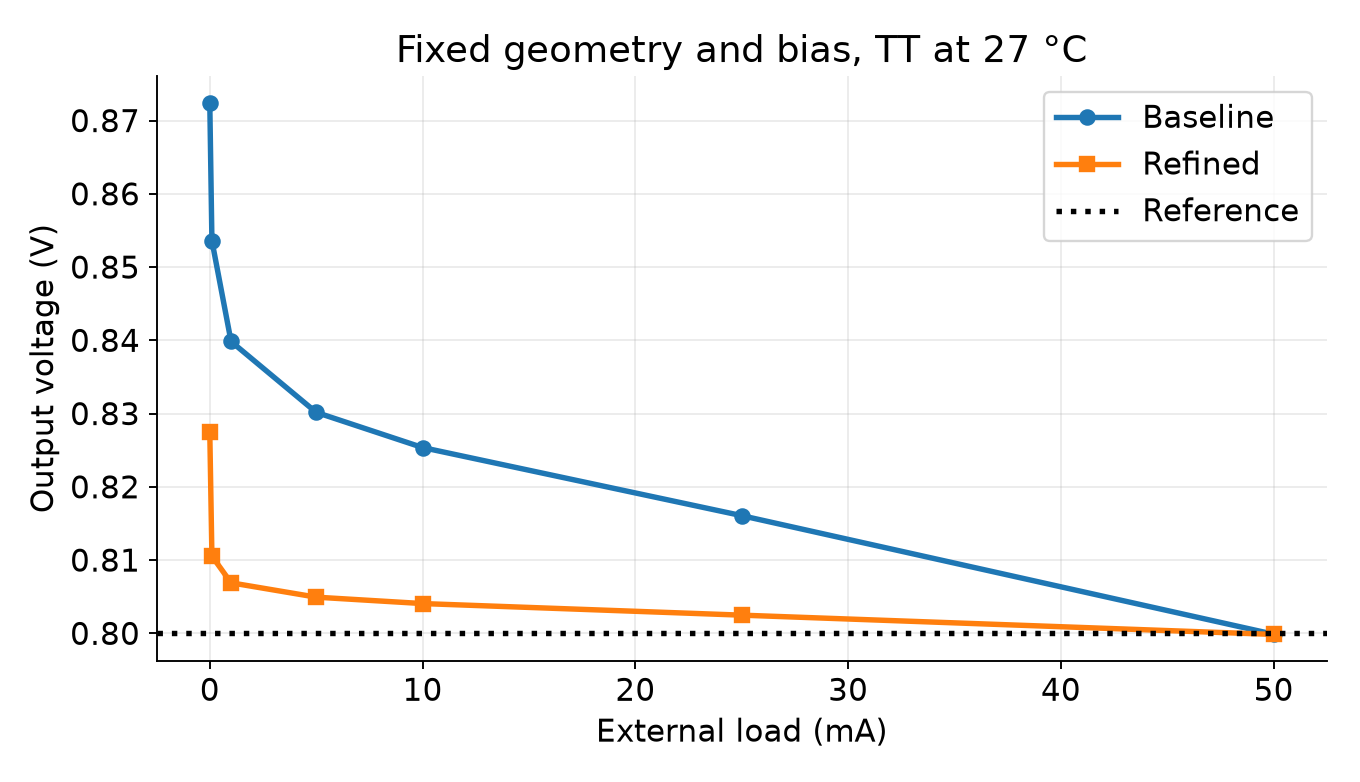

In [4]:
fig, ax = plt.subplots(figsize=(8,4.6))
brows = [r for r in baseline["rows"] if r["corner"] == "tt" and r["temperature_C"] == 27]
ax.plot([r["external_load_A"]*1e3 for r in brows], [r["VOUT_V"] for r in brows], "o-", label="Baseline")
ax.plot([r["external_load_A"]*1e3 for r in rows], [r["voltages_V"]["O"] for r in rows], "s-", label="Refined")
ax.axhline(.8, color="black", linestyle=":", label="Reference")
ax.set(xlabel="External load (mA)", ylabel="Output voltage (V)", title="Fixed geometry and bias, TT at 27 °C")
ax.grid(alpha=.25)
ax.legend()
fig.tight_layout()
fig.savefig(PROJECT / "figures/load_response.pdf")
fig.savefig(PROJECT / "figures/load_response.png", dpi=170)
display(Image(filename=str(PROJECT / "figures" / "load_response.png")))
plt.close(fig)


## Finite driver abstraction and expanded transfer functions

The following two node reduction explains the proposed capacitor before its native comparison. It does not replace the complete transistor circuit. A finite driver resistance RD connects its command voltage to G. Let the command be vD = KI v + A(s)(o − r), with A(s) = A0/(1 + sτA). All lowercase voltages are perturbations. KI represents driver supply sensitivity. The PFET uses gmP and roP. The necessary capacitors remain connected to their actual terminals.

Define CI = CgsP + CFF, CG = CI + CgdP, CO = COUT + CdsP + CgdP, and RΣ = (1/RL + 1/roP)⁻¹. The native external load is an ideal current sink, corresponding to infinite RL in small signal. A finite RL must be included for other load types.

$$\left(1/R_D+sC_G\right)g-\left(A(s)/R_D+sC_{gdP}\right)o
=\left(K_I/R_D+sC_I\right)v-A(s)r/R_D$$
$$\left(g_{mP}-sC_{gdP}\right)g+\left(1/R_\Sigma+sC_O\right)o
=\left(g_{mP}+1/r_{oP}+sC_{dsP}\right)v-i_L.$$

Eliminating g gives a common denominator D(s) = d0 + d1s + d2s² + d3s³ and

$$H_{IN}(s)=\frac{n_0+n_1s+n_2s^2+n_3s^3}{D(s)},\qquad
H_{REF}(s)=\frac{A_0g_{mP}-A_0C_{gdP}s}{D(s)}.$$
$$Z_{OUT}(s)=-\frac{o}{i_L}=
\frac{1+(\tau_A+R_DC_G)s+\tau_AR_DC_Gs^2}{D(s)}.$$

The expanded coefficients are

$$d_0=1/R_\Sigma+A_0g_{mP}$$
$$d_1=C_O+R_DC_G/R_\Sigma+R_DC_{gdP}g_{mP}+\tau_A/R_\Sigma-A_0C_{gdP}$$
$$d_2=R_D(C_GC_O-C_{gdP}^2)+\tau_A C_O+\tau_A R_DC_G/R_\Sigma+\tau_A R_DC_{gdP}g_{mP}$$
$$d_3=\tau_A R_D(C_GC_O-C_{gdP}^2)$$
$$n_0=g_{mP}(1-K_I)+1/r_{oP}$$
$$n_1=C_{dsP}+K_IC_{gdP}+R_Dg_{mP}C_{gdP}+R_DC_G/r_{oP}
+\tau_Ag_{mP}(1-K_I)+\tau_A/r_{oP}$$
$$n_2=R_DC_GC_{dsP}+R_DC_IC_{gdP}+\tau_A C_{dsP}+\tau_A K_IC_{gdP}
+\tau_A R_Dg_{mP}C_{gdP}+\tau_A R_DC_G/r_{oP}$$
$$n_3=\tau_A R_DC_GC_{dsP}+\tau_A R_DC_IC_{gdP}.$$

For the loop cut at the command input to RD, with its physical resistance and all capacitive loading retained, define b0 = 1/RΣ, b1 = CO + RD CG/RΣ + RD CgdP gmP, and b2 = RD(CG CO − CgdP²). The reduced return ratio is

$$T(s)=\frac{A_0(g_{mP}-sC_{gdP})}
{b_0+(b_1+\tau_A b_0)s+(b_2+\tau_A b_1)s^2+\tau_A b_2s^3}.$$

This is the return ratio of the declared reduction, with HREF = T/(1 + T). It is not a separately measured precision or follower return ratio of the full transistor network. For the cubic model, positive denominator coefficients and d1 d2 > d0 d3 are the Hurwitz conditions. Native pole calculations below inspect the larger connected circuit and do not establish gain or phase margins.


## Why common mode tracking does not cancel the output resistance path

The pass current injected into the output, including drain charge in this reduction, is

$$i_P=g_{mP}(v-g)+(v-o)/r_{oP}+sC_{dsP}(v-o)+sC_{gdP}(g-o).$$

When g = v, the gm term vanishes but the remaining disturbance is

$$i_P=\left[1/r_{oP}+s(C_{dsP}+C_{gdP})\right](v-o).$$

At a fixed output, the required complete null instead satisfies

$$\frac{g}{v}=1+\frac{1/r_{oP}+s(C_{dsP}+C_{gdP})}{g_{mP}-sC_{gdP}}.$$

The low frequency value is greater than unity. The denominator also prevents treating the expression as a freely realizable broadband inverse. The next native experiment imposes ideal gate voltages only to measure the isolated pass current sensitivity. It is not the supply rejection of a complete regulator.


In [5]:
run_script("run_pass_disturbance.py")
pass_test = read_result("pass_disturbance/result.json")
print("gmP =", pass_test["gm_S"], "S")
print("roP =", pass_test["ro_ohm"], "ohm")
print("DC ideal null gate gain =", pass_test["low_frequency_correction_gain"])
print("Frequency Hz   Fixed gate A/V   Unity tracking A/V   Ideal null real   Ideal null imag")
for r in pass_test["rows"]:
    print(f'{r["frequency_Hz"]:12.4g}  {r["fixed_gate_current_per_supply_A_per_V"]:14.6g}  '
          f'{r["unity_tracking_current_per_supply_A_per_V"]:18.6g}  '
          f'{r["ideal_null_gate_gain_real"]:15.7f}  {r["ideal_null_gate_gain_imag"]:15.7g}')


run_pass_disturbance.py completed
gmP = 0.48861282975803 S
roP = 15.568849753948218 ohm
DC ideal null gate gain = 1.131455453024472
Frequency Hz   Fixed gate A/V   Unity tracking A/V   Ideal null real   Ideal null imag
           1        0.552844           0.0642308        1.1314555     3.495503e-11
        1000        0.552844           0.0642308        1.1314555     3.495503e-08
       1e+04        0.552844           0.0642308        1.1314555     3.495503e-07
       1e+05        0.552844           0.0642308        1.1314555     3.495503e-06
       1e+06        0.552844           0.0642308        1.1314555     3.495503e-05
    3.02e+06        0.552844           0.0642308        1.1314554     0.0001055625
       1e+07        0.552844            0.064231        1.1314553     0.0003495502
       1e+08        0.552844           0.0642468        1.1314406      0.003495439


## Native comparison of direct supply to gate capacitance

CFF is added physically between VIN and G, in parallel with the pass source to gate coupling. It carries no DC current. It changes both the supply numerator and the connected poles and increases the charge that the driver must move. The tested values are 0, 5, 20, 100 and 500 pF. The transistor dimensions, bias voltages, 50 mA load, 200 pF output capacitor and 100 pF command capacitor remain fixed.

Supply transfer is reported as 20 log10(|vOUT/vIN|). More negative values indicate better rejection. Each curve includes the actual VIN supply disturbance, with the reference and declared bias ports quiet. The source model does not include a physical bias generator whose supply sensitivity could add another disturbance path.


In [6]:
run_script("run_cff_screen.py")
cff = read_result("cff_screen/cff_results.json")
print("CFF pF    1 kHz     10 kHz    100 kHz    1 MHz     3 MHz     10 MHz")
for c in cff["cases"]:
    vals=[r["magnitude_dB"] for r in c["supply"]["samples"] if r["frequency_Hz"] >= 999]
    print(f'{c["CFF_pF"]:6.0f} ' + " ".join(f'{x:9.3f}' for x in vals))


run_cff_screen.py completed
CFF pF    1 kHz     10 kHz    100 kHz    1 MHz     3 MHz     10 MHz
     0   -19.420   -19.407   -18.314   -13.525   -11.417    -4.863
     5   -19.420   -19.407   -18.340   -13.329   -10.193    -3.084
    20   -19.421   -19.408   -18.415   -12.395    -6.973    -0.846
   100   -19.421   -19.414   -18.802    -6.282    -1.113     0.035
   500   -19.421   -19.444   -19.770     0.016     0.035    -0.121


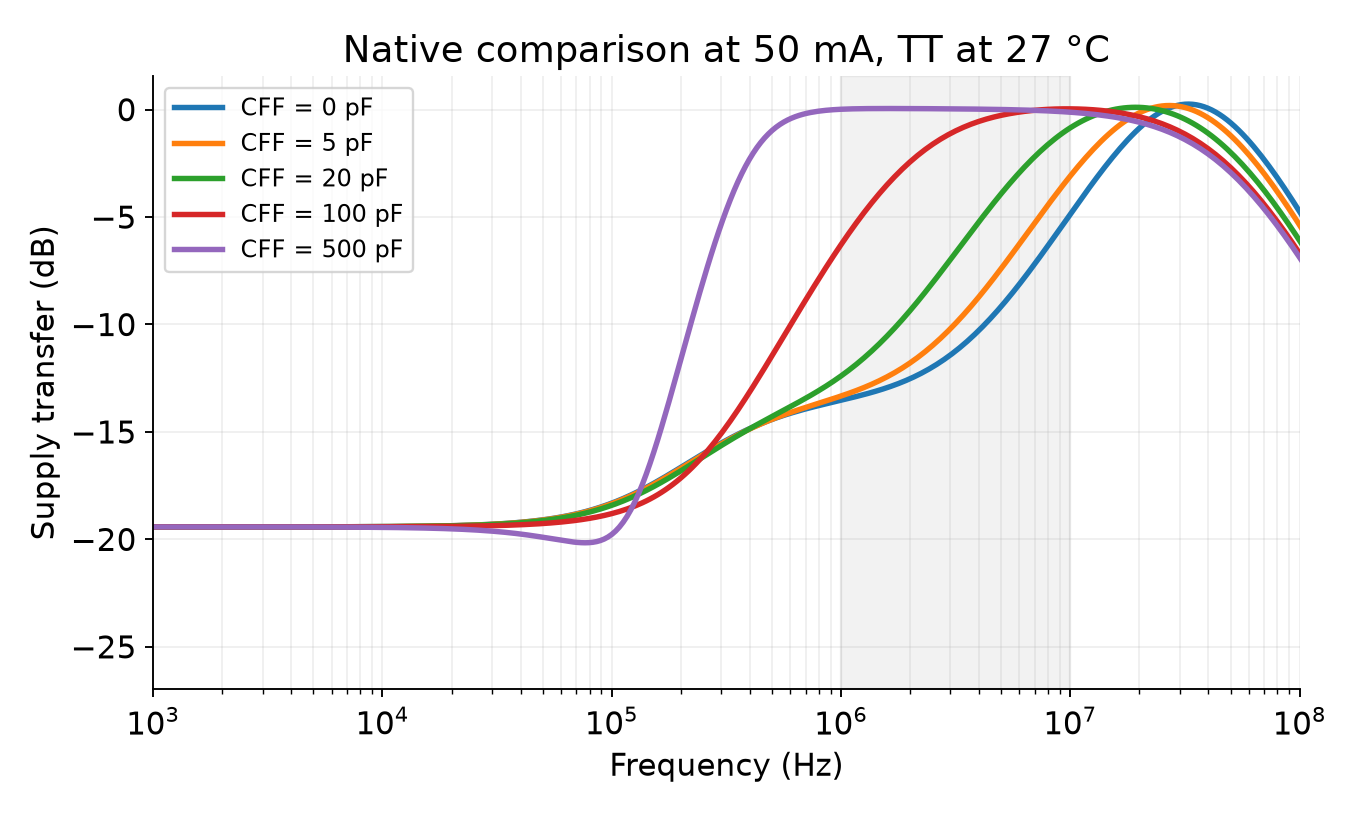

In [7]:
fig, ax=plt.subplots(figsize=(8,4.8))
for c in cff["cases"]:
    trace=np.loadtxt(PROJECT / f'results/cff_screen/cff_{c["CFF_pF"]}pF/supply_ac.txt',skiprows=1)
    ax.semilogx(trace[:,0],20*np.log10(abs(trace[:,1]+1j*trace[:,2])),
                label=f'CFF = {c["CFF_pF"]:g} pF')
ax.axvspan(1e6,1e7,color="grey",alpha=.10)
ax.set(xlabel="Frequency (Hz)",ylabel="Supply transfer (dB)",xlim=(1e3,1e8),
       title="Native comparison at 50 mA, TT at 27 °C")
ax.grid(which="both",alpha=.2)
ax.legend(fontsize=10)
fig.tight_layout()
fig.savefig(PROJECT / "figures/supply_comparison.pdf")
fig.savefig(PROJECT / "figures/supply_comparison.png",dpi=170)
display(Image(filename=str(PROJECT / "figures" / "supply_comparison.png")))
plt.close(fig)


The zero frequency response is unchanged because CFF is open at DC. At 1 MHz the original refined circuit gives a supply transfer of approximately −13.53 dB. The 500 pF case approaches 0 dB. All nonzero tested values worsen the sampled 1 to 10 MHz response. Therefore a direct capacitor cannot be accepted as the requested PSR improvement.

The native pass gate already exhibits a ripple gain above unity. Driving that gain toward unity removes part of the existing correction for the finite output resistance. The appropriate design target is the required complex gate ripple relative to the actual source and output motion, together with the driver current and stability constraints.


In [8]:
print("Native closed pole diagnostics")
for c in cff["cases"]:
    pz=c["pole_diagnostic"]
    assert pz["poles"] and not pz["errors"], "Empty or failed pole diagnostic"
    print("CFF",c["CFF_pF"],"pF:",len(pz["poles"]),"returned poles,",
          pz["RHP_pole_count"],"in the right half plane")


Native closed pole diagnostics
CFF 0 pF: 9 returned poles, 0 in the right half plane
CFF 5 pF: 9 returned poles, 0 in the right half plane
CFF 20 pF: 9 returned poles, 0 in the right half plane
CFF 100 pF: 9 returned poles, 0 in the right half plane
CFF 500 pF: 37 returned poles, 0 in the right half plane


## Load transition and headroom limits

The refined circuit is also subjected to a 5 to 50 to 5 mA load transition with 100 ns edges. This test uses CFF = 0. It is a separate large signal experiment. The 200 pF output capacitor is retained so that a larger capacitor does not hide a gate drive limitation.


run_transient_screen.py completed
Baseline load transition: 5 to 50 to 5 mA, 100 ns edges, COUT 200 pF
initial_output_V                   0.804929 V
rising_load_minimum_output_V       0.467027 V
falling_load_maximum_output_V      0.910240 V
final_output_V                     0.804931 V


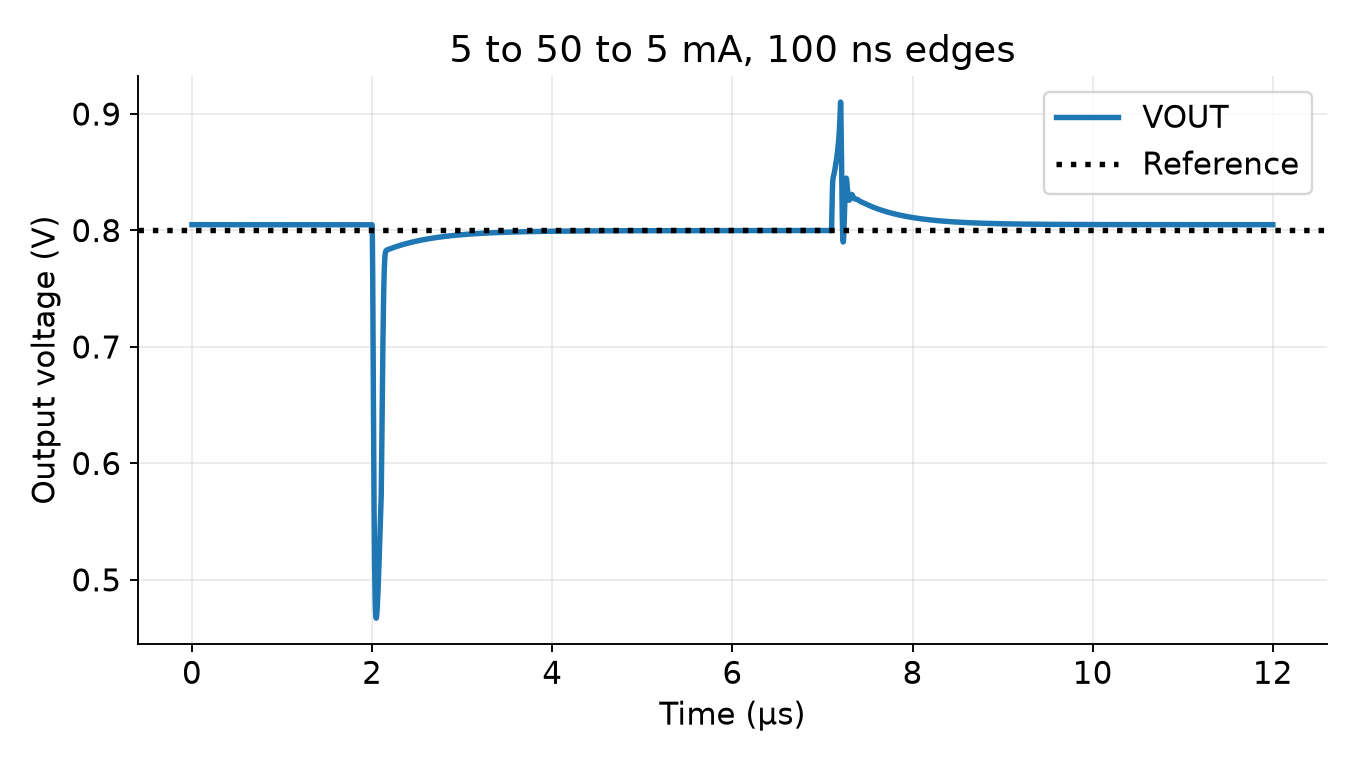

In [9]:
run_script("run_transient_screen.py")
transient=read_result("transient_screen/result.json")
print("Baseline load transition: 5 to 50 to 5 mA, 100 ns edges, COUT 200 pF")
for key in ("initial_output_V", "rising_load_minimum_output_V", "falling_load_maximum_output_V", "final_output_V"):
    print(f"{key:34s} {transient[key]:.6f} V")
d=np.loadtxt(PROJECT / "results/transient_screen/transient.txt",skiprows=1)
fig,ax=plt.subplots(figsize=(8,4.5))
ax.plot(d[:,0]*1e6,d[:,1],label="VOUT")
ax.axhline(.8,color="black",linestyle=":",label="Reference")
ax.set(xlabel="Time (µs)",ylabel="Output voltage (V)",title="5 to 50 to 5 mA, 100 ns edges")
ax.grid(alpha=.25)
ax.legend()
fig.tight_layout()
fig.savefig(PROJECT / "figures/load_transition.pdf")
fig.savefig(PROJECT / "figures/load_transition.png",dpi=170)
display(Image(filename=str(PROJECT / "figures" / "load_transition.png")))
plt.close(fig)


The simulated minimum output is about 0.467 V and the maximum is about 0.910 V. These excursions are not acceptable evidence of a fast transient regulator. At zero external load, the refined output rises to about 0.827 V. MF has only about 18 mV between source and drain while its model saturation voltage is about 50 mV. M2 also loses saturation margin. A nominal 50 mA operating point cannot establish full load range regulation.


## A bounded source connection change

The static headroom hypothesis is tested by moving MF source and body from O to VIN. The new geometry is W = 5 µm, L = 1 µm, nf = 1 and m = 116. Drain G and gate C are retained. Every other transistor, voltage source, load value and capacitor is unchanged. No operating point is retuned between loads. This is a separate supply sourced actuator candidate. It removes the original local follower action.

The original static limitation requires VOUT to exceed VG sufficiently for MF to source current. The new connection instead requires VIN to exceed VG. The voltage room is therefore increased by approximately VIN minus VOUT. The feedback path through the sensing pair remains, while the direct source sensitivity of MF to VOUT is removed. A static improvement does not imply that the original dynamics are preserved.

Load mA    VOUT V    M2 saturation margin mV
    0.0  0.803399                   41.450
    0.1  0.803068                   44.508
    1.0  0.802714                   47.829
    5.0  0.802413                   50.699
   10.0  0.802197                   52.780
   25.0  0.801548                   59.126
   50.0  0.799813                   76.663
Supply transfer samples
1 -61.46115335101912
1000.0 -50.61789999709765
10000.0 -30.987106026711487
100000.0 -10.977623920228833
1000000.0 10.440306614623642
3000000.0 21.761129042122676
10000000.0 6.990436728966598


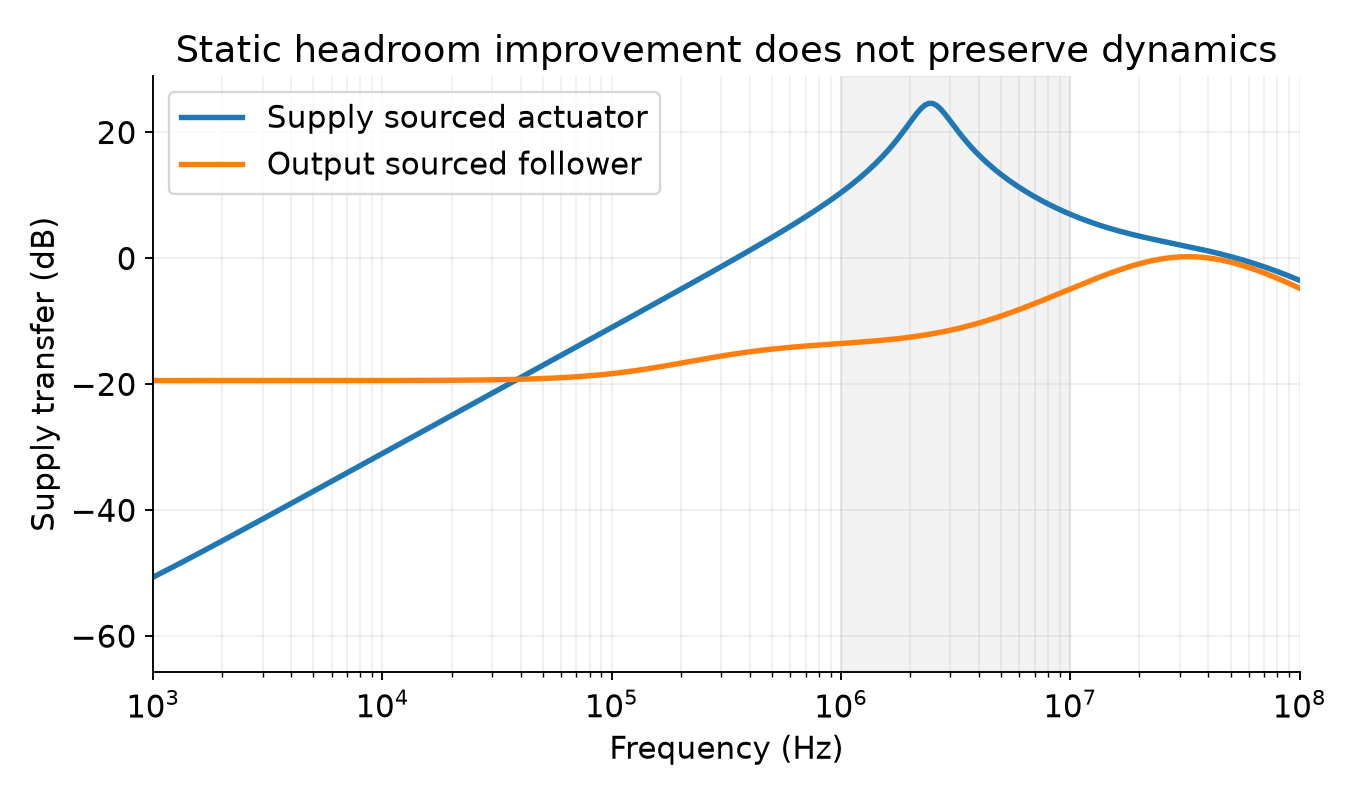

In [10]:
from pathlib import Path
import json, subprocess, sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
PROJECT=Path.cwd()
reply=subprocess.run([sys.executable,str(PROJECT/'scripts/run_supply_actuator.py')],cwd=PROJECT,text=True,capture_output=True,timeout=180)
(PROJECT/'results/run_supply_actuator.py.console.txt').write_text(reply.stdout+'\n'+reply.stderr)
if reply.returncode:
    raise RuntimeError(reply.stdout[-2000:]+reply.stderr[-2000:])
candidate=json.loads((PROJECT/'results/supply_actuator/native_results.json').read_text())
print('Load mA    VOUT V    M2 saturation margin mV')
for r in candidate['load_rows']:
    print(f"{r['external_load_A']*1e3:7.1f}  {r['voltages_V']['O']:.6f}  {r['M2_saturation_margin_V']*1e3:23.3f}")
print('Supply transfer samples')
for r in candidate['AC']['supply']['samples']:
    print(r['frequency_Hz'],r['magnitude_dB'])
trace=np.loadtxt(PROJECT/'results/supply_actuator/supply_ac.txt',skiprows=1)
fig,ax=plt.subplots(figsize=(8,4.7))
ax.semilogx(trace[:,0],20*np.log10(abs(trace[:,1]+1j*trace[:,2])),label='Supply sourced actuator')
original=np.loadtxt(PROJECT/'results/cff_screen/cff_0pF/supply_ac.txt',skiprows=1)
ax.semilogx(original[:,0],20*np.log10(abs(original[:,1]+1j*original[:,2])),label='Output sourced follower')
ax.axvspan(1e6,1e7,color='grey',alpha=.10)
ax.set(xlabel='Frequency (Hz)',ylabel='Supply transfer (dB)',xlim=(1e3,1e8),title='Static headroom improvement does not preserve dynamics')
ax.grid(which='both',alpha=.2)
ax.legend()
fig.tight_layout()
fig.savefig(PROJECT/'figures/supply_actuator_comparison.pdf')
fig.savefig(PROJECT/'figures/supply_actuator_comparison.png',dpi=170)
display(Image(filename=str(PROJECT / "figures" / "supply_actuator_comparison.png")))
plt.close(fig)


The fixed candidate gives VOUT = 0.803399 V at zero external load and 0.799813 V at 50 mA. M2 retains positive saturation margin across the seven tested TT loads. The source move therefore addresses the observed static headroom limitation.

The same candidate fails the MHz rejection objective. Its supply transfer peaks at approximately +24.62 dB near 2.42 MHz. A successful nominal pole calculation with no returned right half plane poles does not make this peaking acceptable. The replacement needs a redesigned local feedback path and compensation. It is not accepted as a drop in replacement for the output sourced follower.

## Power cell and gate driver co design

The selected refinement preserves the original local feedback path through MF. MP changes from L = 0.15 µm and m = 1923 to L = 0.30 µm and m = 2690, with W = 5 µm per unit. Its nominal gate voltage moves from approximately 0.30 V to 0.10 V. This stronger inversion bias reduces the array size required by the longer channel. The native comparison below reports gm, ro and total gate capacitance at each connected operating point.

The selected driver uses MF m = 300, PH m = 6 and NB m = 12. PU is an added PFET with D = G, gate = C, source and body = VIN, W = 5 µm, L = 1 µm and m = 90. BB is set once to 0.668359375 V. BN1 and BN2 remain unchanged. These voltages and dimensions are then fixed across load and corner tests. CAG = 1 pF connects O to G. COUT remains 200 pF and the command capacitor remains 100 pF.

At a fixed output, the low frequency gate ripple needed to cancel the pass current is

$$\left.\frac{g}{v}\right|_{o=0}=1+\frac{1}{g_{mP}r_{oP}}.$$

Increasing ro reduces the required excess over unity. It does not eliminate the gate current and phase requirements. The supply helper injects

$$i_U=g_{mU}(v-c)+(v-g)/r_{oU}$$

into G before its capacitive terms are added. C remains a moving node. The retained local PFET contributes

$$i_F=g_{mF}(o-c)+(o-g)/r_{oF}.$$

Its dependence on o supplies the direct local feedback that was removed by the unsuccessful source replacement. The capacitor adds reciprocal currents

$$i_{G,AG}=sC_{AG}(g-o),\qquad i_{O,AG}=sC_{AG}(o-g).$$

A falling output can therefore pull the pass gate down immediately. The same capacitor also modifies the supply transfer and the feedback zero. In the earlier reduced model, its effect is obtained by replacing CgdP by CgdP + CAG in both node equations and all expanded coefficients. The native comparison retains the complete transistor circuit and the actual capacitor terminals. The full pretest equations and sizing rationale are included in `references/power_refinement.tex`.


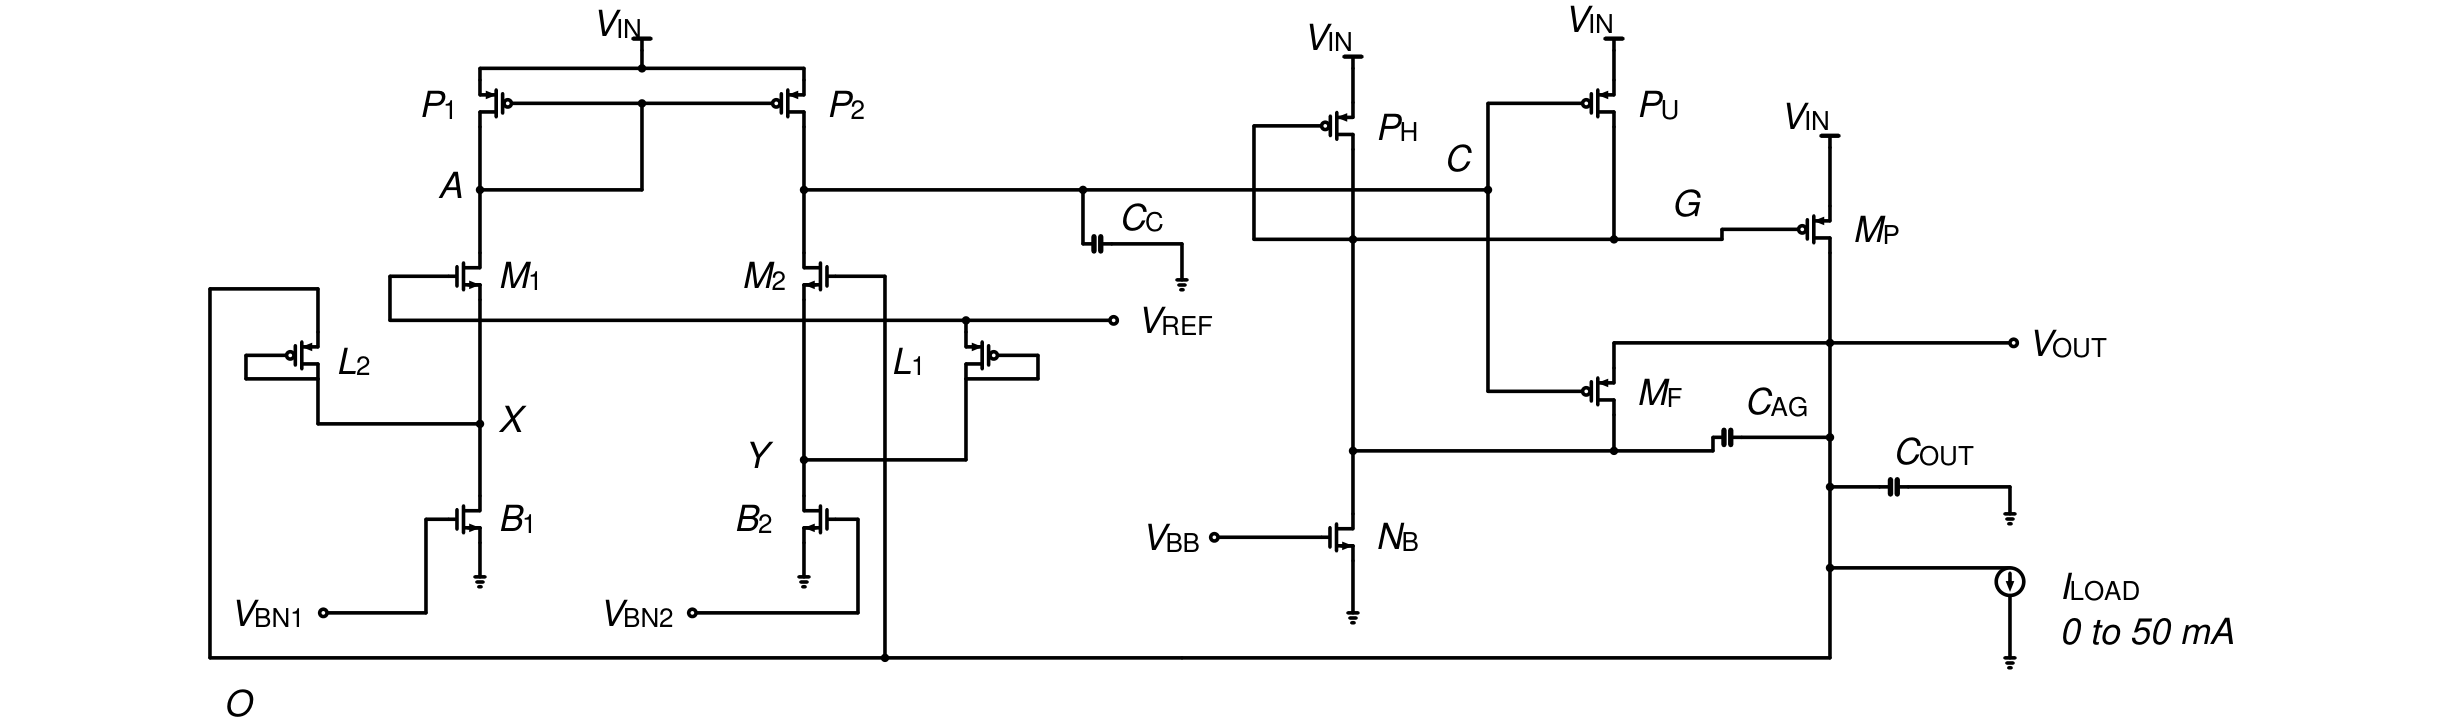

In [11]:
display(Image(filename=str(PROJECT / "figures/power_refinement.png")))


## Expanded reduced transfers of the selected power cell
MP is the integrated PFET pass device with drain O, gate G and source and body VIN. MF has drain G, gate C and source and body O. The added PFET PU has drain G, gate C and source and body VIN. PH is diode connected between VIN and G. NB connects G to ground with a quiet gate bias. The added capacitor $C_{AG}=1$ pF connects O and G. Both of its terminal currents are retained.

The following reduction retains O, G and C as independent dynamic nodes. The unchanged sensing circuit is linearized at the connected operating point. Its internal nodes A, X and Y are eliminated with their local capacitances omitted. Its two remaining terminal currents, defined positive into the sensing circuit, are
$$
\begin{aligned}
i_{C,S}&=c/R_C+gm_{EO}o-gm_{ER}r-gm_{CV}v,\\
i_{O,S}&=gm_{SC}c+o/R_S-gm_{SR}r-gm_{SV}v.
\end{aligned}
$$
These are signed static derivative definitions of the actual sensing network. They retain its output loading and supply sensitivity. In particular, $gm_{EO}$ and $gm_{ER}$ are not assumed equal. They do not introduce a new ideal amplifier. All transistor $gm$ and $ro$ values are evaluated at the same connected bias point.

This model omits the internal sensing poles and uses reciprocal $C_{gs}$, $C_{gd}$ and $C_{ds}$ elements for the retained transistors. It is an explicit topology reduction, not a fitted native MHz model or a complete internal stability test. The native simulations retain their original compact model charge.

Write H for PH, N for NB and U for PU. Define only resistance and capacitance combinations
$$
\begin{aligned}
R_G&=ro_F\parallel ro_U\parallel ro_H\parallel ro_N,\\
R_O&=R_L\parallel R_S\parallel ro_P\parallel ro_F,\\
C_Q&=C_{gdF}+C_{gdU},& C_S&=C_{gsF},\\
C_T&=C_{gdP}+C_{dsF}+C_{AG},\\
C_H&=C_{gsH}+C_{dsH},& C_N&=C_{gdN}+C_{dsN},\\
C_C&=C_{CMD}+C_S+C_{gsU}+C_Q,\\
C_G&=C_{gsP}+C_Q+C_T+C_{dsU}+C_H+C_N,\\
C_O&=C_{OUT}+C_{dsP}+C_S+C_T,\\
C_{IG}&=C_{gsP}+C_{dsU}+C_H.
\end{aligned}
$$
Here $C_{CMD}=100$ pF and $C_{OUT}=200$ pF. An ideal constant current load has $R_L\to\infty$. PH has no independent gate to drain capacitor because those terminals are shorted. NB gate capacitance to its quiet bias is retained in $C_N$.

### Physical node equations
With $v=v_{in}$ and $r=v_{ref}$, the command equation is
$$
(1/R_C+sC_C)c-sC_Qg+(gm_{EO}-sC_S)o
=(gm_{CV}+sC_{gsU})v+gm_{ER}r.
$$
The finite gate equation is
$$
\begin{aligned}
&(gm_F+gm_U-sC_Q)c+(gm_H+1/R_G+sC_G)g
-(gm_F+1/ro_F+sC_T)o\\
&\hspace{10mm}=(gm_H+1/ro_H+gm_U+1/ro_U+sC_{IG})v.
\end{aligned}
$$
The output equation is
$$
\begin{aligned}
&(gm_{SC}-gm_F-sC_S)c+(gm_P-1/ro_F-sC_T)g
+(gm_F+1/R_O+sC_O)o\\
&\hspace{10mm}=(gm_P+1/ro_P+gm_{SV}+sC_{dsP})v+gm_{SR}r-i_L.
\end{aligned}
$$
The terms containing $gm_F$ and $ro_F$ occur at both G and O because MF draws its source current from O. PU contributes source current from VIN and loads C through $C_{gsU}$ and $C_{gdU}$. The $C_{AG}$ contribution increases both $C_G$ and $C_O$ and the reciprocal coupling $C_T$.

### Explicit polynomial coefficients
Define the following real coefficients directly from the physical parameters:
$$
\begin{aligned}
a_0&=(gm_F+gm_U)(gm_P-1/ro_F)-(gm_H+1/R_G)(gm_{SC}-gm_F),\\
a_1&=-(gm_F+gm_U)C_T-C_Q(gm_P-1/ro_F)
+(gm_H+1/R_G)C_S-C_G(gm_{SC}-gm_F),\\
a_2&=C_QC_T+C_GC_S,\\
b_0&=-(gm_P-1/ro_F)/R_C,\\
b_1&=C_T/R_C-C_C(gm_P-1/ro_F)-C_Q(gm_{SC}-gm_F),\\
b_2&=C_CC_T+C_QC_S,\\
c_0&=(gm_H+1/R_G)/R_C,\\
c_1&=C_G/R_C+C_C(gm_H+1/R_G)+C_Q(gm_F+gm_U),\\
c_2&=C_CC_G-C_Q^2.
\end{aligned}
$$
The expanded common denominator is $D(s)=d_0+d_1s+d_2s^2+d_3s^3$, with
$$
\begin{aligned}
d_0&=gm_{EO}a_0-(gm_F+1/ro_F)b_0+(gm_F+1/R_O)c_0,\\
d_1&=gm_{EO}a_1-C_Sa_0-(gm_F+1/ro_F)b_1-C_Tb_0
+(gm_F+1/R_O)c_1+C_Oc_0,\\
d_2&=gm_{EO}a_2-C_Sa_1-(gm_F+1/ro_F)b_2-C_Tb_1
+(gm_F+1/R_O)c_2+C_Oc_1,\\
d_3&=C_CC_GC_O-C_CC_T^2-C_Q^2C_O-2C_QC_SC_T-C_GC_S^2.
\end{aligned}
$$
The coefficients $a_i$, $b_i$ and $c_i$ are explicitly listed polynomial coefficients, not unresolved determinants or frequency dependent quantities. For example, the DC term is also
$$
\begin{aligned}
d_0={}&gm_{EO}\left[(gm_F+gm_U)(gm_P-1/ro_F)
 -(gm_H+1/R_G)(gm_{SC}-gm_F)\right]\\
&+\frac{(gm_F+1/ro_F)(gm_P-1/ro_F)}{R_C}
+\frac{(gm_F+1/R_O)(gm_H+1/R_G)}{R_C}.
\end{aligned}
$$

The supply numerator $N_V(s)=v_0+v_1s+v_2s^2+v_3s^3$ has coefficients
$$
\begin{aligned}
v_0={}&gm_{CV}a_0+(gm_H+1/ro_H+gm_U+1/ro_U)b_0
+(gm_P+1/ro_P+gm_{SV})c_0,\\
v_1={}&gm_{CV}a_1+C_{gsU}a_0
+(gm_H+1/ro_H+gm_U+1/ro_U)b_1+C_{IG}b_0\\
&+(gm_P+1/ro_P+gm_{SV})c_1+C_{dsP}c_0,\\
v_2={}&gm_{CV}a_2+C_{gsU}a_1
+(gm_H+1/ro_H+gm_U+1/ro_U)b_2+C_{IG}b_1\\
&+(gm_P+1/ro_P+gm_{SV})c_2+C_{dsP}c_1,\\
v_3={}&C_{gsU}a_2+C_{IG}b_2+C_{dsP}c_2.
\end{aligned}
$$
The reference numerator $N_R(s)=r_0+r_1s+r_2s^2$ has coefficients
$$
\begin{aligned}
r_0&=gm_{ER}a_0+gm_{SR}c_0,\\
r_1&=gm_{ER}a_1+gm_{SR}c_1,\\
r_2&=gm_{ER}a_2+gm_{SR}c_2.
\end{aligned}
$$
The requested reduced transfer functions are therefore
$$
\begin{aligned}
H_{VIN}(s)&=\frac{v_0+v_1s+v_2s^2+v_3s^3}{d_0+d_1s+d_2s^2+d_3s^3},\\
H_{VREF}(s)&=\frac{r_0+r_1s+r_2s^2}{d_0+d_1s+d_2s^2+d_3s^3}.
\end{aligned}
$$
The load response is $o/i_L=-(c_0+c_1s+c_2s^2)/D(s)$. Supply transfer is defined with the reference and bias ports quiet. Reference transfer is defined with VIN and the bias ports quiet.

### Two declared ordered loop returns
Set all independent small signal sources to zero. The first closure restores the entire MF controlled current $gm_F(c-o)$ between G and O while the sensing current $gm_{EO}o$ at C is opened. The second closure restores that sensing current with MF already closed. Every $ro$ and capacitance remains connected in both openings. The static sensing output coupling $gm_{SC}$ also remains connected.

The first closure numerator is $F(s)=f_0+f_1s+f_2s^2$, where
$$
\begin{aligned}
f_0&=\frac{gm_F}{R_C}(gm_P-1/ro_F+gm_H+1/R_G),\\
f_1&=gm_F\left[\frac{C_G-C_T}{R_C}
+(C_C-C_S)(gm_P-1/ro_F+gm_H+1/R_G)
+C_Q(gm_{SC}+gm_U-1/ro_F+1/R_O)\right],\\
f_2&=gm_F\left[(C_C-C_S)(C_G-C_T)
+C_Q(C_O-C_S-C_T-C_Q)\right].
\end{aligned}
$$
The sensing closure numerator is $E(s)=gm_{EO}(a_0+a_1s+a_2s^2)$. The explicit ordered return ratios are
$$
\begin{aligned}
T_F(s)&=\frac{f_0+f_1s+f_2s^2}
{(d_0-gm_{EO}a_0-f_0)+(d_1-gm_{EO}a_1-f_1)s
+(d_2-gm_{EO}a_2-f_2)s^2+d_3s^3},\\
T_E(s)&=\frac{gm_{EO}(a_0+a_1s+a_2s^2)}
{(d_0-gm_{EO}a_0)+(d_1-gm_{EO}a_1)s
+(d_2-gm_{EO}a_2)s^2+d_3s^3}.
\end{aligned}
$$
These are the two declared closures of the selected model. They are not independently measured connected loop gains and must not be multiplied as such. They are not measurements of native loop margin or a test of every internal mode. Opening MF removes its controlled current at both terminals, rather than deleting only a presumed output feedback term.

### Checks and interpretation
No coefficient at DC depends on $C_{AG}$. At fixed transistor parameters each denominator and numerator coefficient is affine in $C_{AG}$. Apparent quadratic terms cancel because the capacitor is reciprocal. A model that changes only the gate equation fails this identity. The cubic coefficient is the determinant of the retained reciprocal capacitance matrix, expanded above without a matrix operation.

The helper changes the supply numerator as well as the denominator. Its supply referenced current can assist gate ripple tracking, while its finite $ro_U$ and terminal capacitances modify feedback and loading. It therefore cannot be replaced by an ideal gate command. The longer pass transistor changes $gm_P$, $ro_P$ and all pass capacitances together. Neither an isolated $ro$ improvement nor an added charge path proves improved connected PSR.

The explicit coefficients were checked against independent direct solutions of the three node equations in 1000 synthetic parameter cases. The maximum relative discrepancies were $1.78\times10^{-12}$ for supply transfer, $1.11\times10^{-13}$ for reference transfer and $5.12\times10^{-12}$ for load response. The denominator and affine $C_{AG}$ identities were checked separately. This is an algebra verification of the declared reduction. It is not native model validation, a proof of all internal modes, or a loop margin measurement.


In [12]:
run_script("check_power_equations.py")
algebra = read_result("analytical/power_equations_check.json")
print(algebra["evidence"])
print("Transfer evaluations:", algebra["transfer_evaluations"])
print("Ordered loop evaluations:", algebra["ordered_loop_evaluations"])
print("Maximum normalized discrepancy:", max(algebra["maximum_relative_errors"].values()))


check_power_equations.py completed
Synthetic algebra check of a selected three node model only. No native simulation or qualification.
Transfer evaluations: 3000
Ordered loop evaluations: 2000
Maximum normalized discrepancy: 5.1180619768259746e-12


In [13]:
run_script("run_power_refinement.py")
power = read_result("power_refinement/summary.json")
selected = power["selected"]
original = power["original"]
print("Same external load: 50 mA, VIN 1.2 V, VREF 0.8 V, TT at 27 C")
print("Quantity                         Original          Selected")
a, b = original["dc_50mA"], selected["dc_50mA"]
for label, x, y in [
    ("Output V",a["voltages_V"]["O"],b["voltages_V"]["O"]),
    ("VIN overhead uA",a["core_VIN_overhead_A"]*1e6,b["core_VIN_overhead_A"]*1e6),
    ("Separate reference current uA",a["reference_current_A"]*1e6,b["reference_current_A"]*1e6),
    ("Pass gm S",a["MP_gm_S"],b["MP_gm_S"]),
    ("Pass ro ohm",a["MP_ro_ohm"],b["MP_ro_ohm"]),
    ("Pass gate capacitance pF",original["gate_charge"]["CGG_F"]*1e12,selected["gate_capacitance_F"]*1e12)]:
    print(f"{label:30s} {x:15.7g} {y:17.7g}")
print("The reference current and generator power are not included in VIN overhead.")
r = selected["reference_samples"][0]
print(f"Selected reference gain at 1 Hz: {r['real']:.6f} V/V, {r['magnitude_dB']:.3f} dB")
print("Band        Minimum improvement dB    Maximum improvement dB    Samples")
for name, r in selected["bands_vs_original"].items():
    print(f"{name:8s} {r['minimum_improvement_dB']:25.4f} {r['maximum_improvement_dB']:25.4f} {r['sample_count']:10d}")


run_power_refinement.py completed
Same external load: 50 mA, VIN 1.2 V, VREF 0.8 V, TT at 27 C
Quantity                         Original          Selected
Output V                             0.7998414          0.799378
VIN overhead uA                       52.90502          105.3039
Separate reference current uA          13.3924          13.42567
Pass gm S                            0.4886128         0.4780966
Pass ro ohm                           15.56885          64.15063
Pass gate capacitance pF              10.18311          24.38256
The reference current and generator power are not included in VIN overhead.
Selected reference gain at 1 Hz: 0.932678 V/V, -0.605 dB
Band        Minimum improvement dB    Maximum improvement dB    Samples
LF                          1.0143                    1.9391        121
MHz                         4.4495                    4.9170         61


Frequency Hz    Original dB    Selected dB    Improvement dB
           1       -19.4206       -20.4348            1.0142
        1000       -19.4205       -20.4348            1.0143
       1e+04       -19.4067       -20.4328            1.0262
       1e+05       -18.3143       -20.2534            1.9391
       1e+06       -13.5252       -18.2703            4.7451
       3e+06       -11.4171       -16.3163            4.8992
       1e+07        -4.8627        -9.3122            4.4495


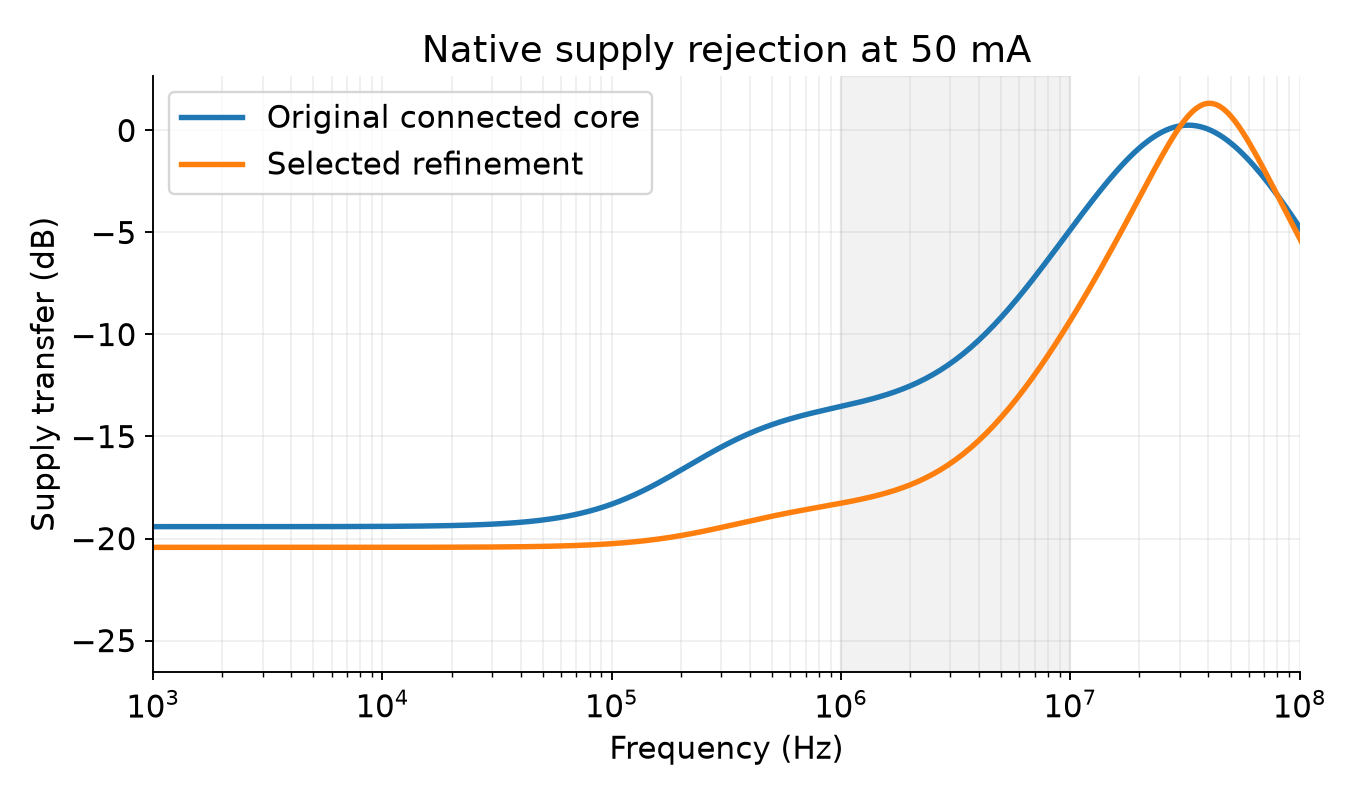

In [14]:
print("Frequency Hz    Original dB    Selected dB    Improvement dB")
for a,b in zip(original["supply"]["samples"],selected["supply_samples"]):
    print(f'{a["frequency_Hz"]:12.4g} {a["magnitude_dB"]:14.4f} {b["magnitude_dB"]:14.4f} {a["magnitude_dB"]-b["magnitude_dB"]:17.4f}')
fig,ax=plt.subplots(figsize=(8,4.7))
for label,file in [("Original connected core","original_ac.txt"),("Selected refinement","selected_ac.txt")]:
    d=np.loadtxt(PROJECT / "results/power_refinement" / file,skiprows=1)
    ax.semilogx(d[:,0],20*np.log10(abs(d[:,1]+1j*d[:,2])),label=label)
ax.axvspan(1e6,1e7,color="grey",alpha=.1)
ax.set(xlabel="Frequency (Hz)",ylabel="Supply transfer (dB)",xlim=(1e3,1e8),title="Native supply rejection at 50 mA")
ax.grid(which="both",alpha=.2)
ax.legend()
fig.tight_layout()
fig.savefig(PROJECT / "figures/final_psr.png",dpi=170)
fig.savefig(PROJECT / "figures/final_psr.pdf")
plt.close(fig)
display(Image(filename=str(PROJECT / "figures/final_psr.png")))


## Load range and transient comparison

The selected circuit is tested at zero external load and six additional loads through 50 mA. The bias voltages are held fixed. Reported saturation margins are the local model values of the relevant terminal voltage minus the magnitude of its saturation voltage. Positive margins at these operating points establish the tested static headroom, not a process wide guarantee.

The transient test uses 5 to 50 to 5 mA, with 100 ns edges, and the same 200 pF output capacitor for both circuits. The comparison therefore attributes the change to the declared pass cell, gate driver and 1 pF charge path.


Load mA   VOUT V   M2 margin mV   MF margin mV   NB margin mV
    0.0  0.806955         12.572        238.534        453.032
    0.1  0.806294         17.312        283.168        407.858
    1.0  0.804819         28.966        388.459        301.392
    5.0  0.803514         40.395        481.444        207.422
   10.0  0.802835         46.690        525.035        163.347
   25.0  0.801519         59.420        591.225         96.284
   50.0  0.799378         81.151        653.612         32.551
Observable supply transfer pole diagnostics
0.0 mA: 46 returned poles, 0 in the right half plane
5.0 mA: 31 returned poles, 0 in the right half plane
50.0 mA: 46 returned poles, 0 in the right half plane
Load transition quantity             Original V    Selected V
initial_output_V                       0.804929      0.803514
rising_load_minimum_output_V           0.467027      0.536951
falling_load_maximum_output_V          0.910240      0.890661
final_output_V                         0.8049

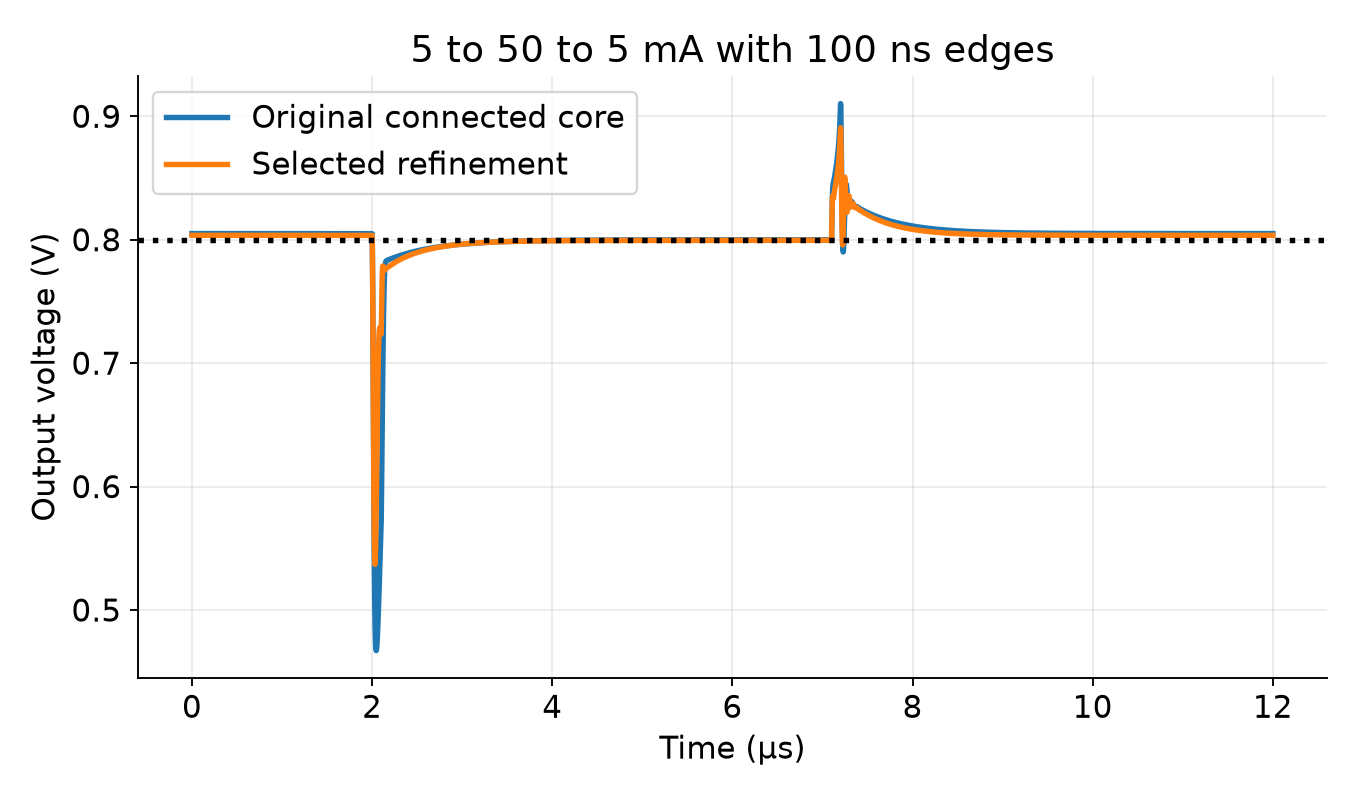

In [15]:
print("Load mA   VOUT V   M2 margin mV   MF margin mV   NB margin mV")
for r in selected["load_rows"]:
    print(f'{r["external_load_A"]*1e3:7.1f} {r["voltages_V"]["O"]:9.6f} '
          f'{r["M2_saturation_margin_V"]*1e3:14.3f} {r["MF_forward_saturation_margin_V"]*1e3:14.3f} {r["NB_saturation_margin_V"]*1e3:14.3f}')
print("Observable supply transfer pole diagnostics")
for r in selected["poles_by_load"]:
    assert r["poles"], "Empty pole diagnostic"
    print(r["load_A"]*1e3,"mA:",len(r["poles"]),"returned poles,",r["RHP_pole_count"],"in the right half plane")
print("Load transition quantity             Original V    Selected V")
for key in ("initial_output_V", "rising_load_minimum_output_V", "falling_load_maximum_output_V", "final_output_V"):
    print(f"{key:35s} {original['transient'][key]:11.6f} {selected['transient'][key]:13.6f}")
fig,ax=plt.subplots(figsize=(8,4.7))
for label,file in [("Original connected core","original_transient.txt"),("Selected refinement","selected_transient.txt")]:
    d=np.loadtxt(PROJECT / "results/power_refinement" / file,skiprows=1)
    ax.plot(d[:,0]*1e6,d[:,1],label=label)
ax.axhline(.8,color="black",linestyle=":")
ax.set(xlabel="Time (µs)",ylabel="Output voltage (V)",title="5 to 50 to 5 mA with 100 ns edges")
ax.grid(alpha=.25)
ax.legend()
fig.tight_layout()
fig.savefig(PROJECT / "figures/final_transient.png",dpi=170)
fig.savefig(PROJECT / "figures/final_transient.pdf")
plt.close(fig)
display(Image(filename=str(PROJECT / "figures/final_transient.png")))


## Selection and the retained tradeoffs

The final driver scale and CAG are selected using a joint nominal rule: no degradation at any sampled frequency in either the 1 kHz to 100 kHz band or the 1 to 10 MHz band, improvement in both declared transient extrema relative to the original circuit, positive tested DC headroom, and no returned right half plane poles at 0, 5 and 50 mA. Among passing candidates, the greatest minimum MHz improvement is preferred. This is a selection rule for the declared experiments, not a general stability proof or an assertion of competitive absolute performance.

Increasing CAG helps the transient while progressively changing the supply response. Increasing driver current improves the charge rate at a cost in overhead. The following table retains that tradeoff, including rejected points.


In [16]:
print("Scale   CAG pF   Min MHz gain dB   Min VOUT V   Max VOUT V   RHP poles")
for r in power["driver_cases"]:
    rhs=sum(x["RHP_pole_count"] for x in r["pole_diagnostics"])
    t=r["transient"]
    print(f'{r["driver_scale"]:5d} {r["CAG_pF"]:8.1f} {r["bands_vs_original"]["MHz"]["minimum_improvement_dB"]:17.4f} '
          f'{t["rising_load_minimum_output_V"]:12.6f} {t["falling_load_maximum_output_V"]:12.6f} {rhs:11d}')
print("CAG sweep at driver scale 2")
print("CAG pF    Min MHz gain dB    Min VOUT V    Max VOUT V")
for r in power["cag_cases"]:
    t = r["transient"]
    print(f"{r['CAG_pF']:6.1f} {r['bands_vs_original']['MHz']['minimum_improvement_dB']:18.4f} "
          f"{t['rising_load_minimum_output_V']:13.6f} {t['falling_load_maximum_output_V']:13.6f}")


Scale   CAG pF   Min MHz gain dB   Min VOUT V   Max VOUT V   RHP poles
    3      1.0            4.4495     0.536951     0.890661           0
    3      2.0            2.7014     0.575408     0.891449           0
    4      1.0            4.3419     0.616261     0.882723           0
    4      2.0            4.3313     0.635536     0.883413          23
CAG sweep at driver scale 2
CAG pF    Min MHz gain dB    Min VOUT V    Max VOUT V
   0.0             4.6142      0.177134      0.902704
   1.0             2.0324      0.361697      0.903617
   2.0             0.2593      0.447157      0.904453
   3.0            -0.9890      0.494367      0.905353
   5.0            -2.8150      0.540944      0.907040
  20.0            -8.5240      0.592614      0.918371
  50.0           -11.4146      0.612260      0.933664
 100.0           -12.9626      0.621405      0.945884


## Fixed bias corner screen and remaining design scope

The selected dimensions and bias voltages are also evaluated at SS and FF at 27 °C, and TT at 0 and 85 °C, each at 50 mA. No corner dependent rebias is performed. The one percent output column is a clearly declared screening threshold around 0.8 V. This bounded table does not replace full process, voltage, temperature, load and mismatch coverage.


In [17]:
print("Corner   Temp C   VOUT V   One percent   NB margin mV   PSR 1MHz dB   PSR 10MHz dB   RHP poles")
for r in selected["corner_rows"]:
    spots={int(x["frequency_Hz"]):x["magnitude_dB"] for x in r["supply"]["samples"]}
    print(f'{r["corner"]:6s} {r["temperature_C"]:7.1f} {r["dc"]["voltages_V"]["O"]:9.6f} '
          f'{str(r["within_one_percent_output"]):11s} {r["dc"]["NB_saturation_margin_V"]*1e3:14.3f} '
          f'{spots[1000000]:13.3f} {spots[10000000]:14.3f} {r["pole_diagnostics"]["RHP_pole_count"]:9d}')


Corner   Temp C   VOUT V   One percent   NB margin mV   PSR 1MHz dB   PSR 10MHz dB   RHP poles
ss        27.0  0.784065 False               -7.884         1.212          2.065         0
ff        27.0  0.806386 True                67.105       -15.756        -13.269         0
tt         0.0  0.796087 True                -0.606        -3.260         -0.823         0
tt        85.0  0.802490 True               102.362       -21.968        -15.389         0


In [18]:
run_script("check_reproduction.py")
check = read_result("REPRODUCTION_CHECK.json")
print("Reproduction comparison passed for the recorded baseline, alternatives and selected circuit.")
print(f"Selected DC maximum difference: {check['maximum_selected_output_difference_V']:.3g} V")
print(f"Selected AC maximum difference: {check['maximum_selected_AC_difference_dB']:.3g} dB")
print(f"Selected transient extrema maximum difference: {check['maximum_selected_transient_extrema_difference_V']:.3g} V")


check_reproduction.py completed
Reproduction comparison passed for the recorded baseline, alternatives and selected circuit.
Selected DC maximum difference: 0 V
Selected AC maximum difference: 0 dB
Selected transient extrema maximum difference: 0 V


## Findings and reproducibility boundary

The measured nominal improvement comes from treating pass resistance, gate charge, finite driver current and the local feedback path together. The longer pass device alone did not improve the entire band. Replacing the output sourced follower with a supply sourced transistor improved static voltage room but removed useful local feedback. Direct VIN to gate capacitance and excessive output to gate capacitance also failed the joint criterion. The final circuit retains the local follower and combines the power cell change with a parallel helper, adequate driver current and a small reciprocal charge path.

The absolute load transition excursion remains substantial. The fixed bias corner screen also exposes a specific failure: NB loses saturation at SS 27 °C and TT 0 °C. At SS 27 °C, supply transfer becomes positive at 1 and 10 MHz, despite the nominal improvement. Consequently the selected result does not establish PVT robust supply rejection. Bias and headroom control require further design. The next physical change should address the available drain voltage of NB and the bias dependence of the pass gate position. Reducing the NB saturation voltage at the required sink current, or introducing a physical bias circuit that follows process and temperature, are candidates. Either change alters gate loading and supply coupling and must be checked in the connected circuit. They are not implemented results.

Startup, mismatch, physical bias and reference generation, realistic diffusion geometry, layout extraction and complete internal loop margins also remain open. Observable transfer poles are a diagnostic and do not establish every internal mode. All tests use ideal external reference and bias ports, and core overhead excludes their generator power. These are concrete remaining implementation requirements.

Additional driver and compensation studies are preserved in `results/recorded/driver_refinement_summary.json` and `results/recorded/compensation_screen_summary.json`, with their equations under `references`. They are not substituted for successful connected measurements. The optional compensation grid runner is separate from the main notebook so that the recorded search can be inspected without executing every rejected point.

## Sources and license

The simulator is [ngspice](https://ngspice.sourceforge.io/). The device model source is the [official SKY130 primitive library](https://github.com/google/skywater-pdk-libs-sky130_fd_pr) at commit `f62031a1be9aefe902d6d54cddd6f59b57627436`. Original licenses, generated model hashes and source provenance are included. The project uses Apache License 2.0. This notebook and its supporting files are maintained in the [idea2 branch](https://github.com/christianreivan/sscs-ose-code-a-chip.github.io/tree/idea2/ISSCC27/submitted_notebooks/sky130_pfet_ldo).
